# Week6_ex4_analysis - Force Between Two Block Magnets vs Gap

![Week6_ex4 result](Images/Week6_ex4_result_image.png)

Maxwell 3D Magnetostatic. Two N42 blocks, 20 (x) × 10 (y) × 100 (z) mm, are stacked along y with a gap swept from 2 to 20 mm. The force on the lower block (`magnet1`) is a virtual force, re-solved at each gap in a Python loop. N42 is defined in the notebook with $\mu_r = 1.05$ and $H_c = 970116$ A/m ($B_r = 1.28$ T).

Both blocks use the same `N42` material, and the face coordinate systems they're attached to are only shifted, not rotated. So both are magnetized along +y, even though the original markdown says "opposite directions". Two magnets magnetized the same way and stacked along that axis face each other N-to-S, so they should attract. The lower block should get a positive $F_y$, and $F_x$, $F_z$ should vanish by symmetry.

This is a light check with no hypotheses, done the same way as the cylinder pair in Week5_ex1. Each block is replaced by surface charges $\pm M$ on its two y-faces (closed-form field of a charged rectangle), and $M$ is corrected for the magnet's recoil permeability. The FEM CSV had already been opened before the model was run, so this is **not a blind prediction**, but no FEM number is used anywhere in the model.

$$F_y = \mu_0 \sum_{\text{faces of }1} \sigma_1 \int H_{y,2}\,dA,\qquad M = \frac{\mu_r H_c}{1 + \chi\,(N_\text{self} - N_\text{mut})},\quad \chi = \mu_r - 1$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Force table exported by the original notebook's gap loop
fem = pd.read_csv("Week6_ex4_force.csv")
fem["|F_x|/F_y [%]"] = 100 * fem["Force_x_N"].abs() / fem["Force_y_N"]
fem["|F_z|/F_y [%]"] = 100 * fem["Force_z_N"].abs() / fem["Force_y_N"]
fem.round(4)

,Gap_mm,Force_mag_N,Force_x_N,Force_y_N,Force_z_N,|F_x|/F_y [%],|F_z|/F_y [%]
0,2,326.5449,-0.7828,326.5440,0.1025,0.2397,0.0314
1,4,240.7489,-0.3704,240.7486,0.0080,0.1539,0.0033
2,6,183.9083,0.0004,183.9082,0.1471,0.0002,0.0800
3,8,143.9357,-0.0537,143.9357,-0.0697,0.0373,0.0484
4,10,114.8797,0.1803,114.8795,0.0644,0.1569,0.0561
5,12,92.7800,-0.1714,92.7797,-0.1093,0.1847,0.1178
6,14,75.8857,0.0484,75.8857,0.0308,0.0638,0.0406
7,16,62.7969,0.0989,62.7968,-0.0260,0.1575,0.0414
8,18,52.5706,0.2210,52.5701,-0.0228,0.4204,0.0434
9,20,44.3458,-0.3040,44.3448,-0.0399,0.6856,0.0900


$F_y$ is positive at every gap, so the lower block is pulled up toward the upper one. That's attraction, which fits both blocks being magnetized along +y. The side components stay below 0.8 N in absolute terms (under 0.7% of $F_y$, largest at 20 mm where $F_y$ itself is smallest). They wander in sign from gap to gap, so they're mesh noise on a symmetric problem.

In [2]:
# 2. Charged-rectangle field (only H_y is needed: both blocks' charges sit on y-faces)
mu0 = 4e-7 * np.pi
mm = 1e-3
mu_r, Hc = 1.05, 970116.0              # N42 as defined in the original notebook
chi = mu_r - 1
M_rigid = mu_r * Hc
W_, H_, D_ = 20 * mm, 10 * mm, 100 * mm

def Hy_sheet(x, y, z, x1, x2, z1, z2, y0, sigma):
    d = y - y0
    out = np.zeros_like(x)
    for xs, sx in ((x1, 1), (x2, -1)):
        for zs, sz in ((z1, 1), (z2, -1)):
            u, v = x - xs, z - zs
            out += sx * sz * np.arctan(u * v / (d * np.sqrt(u * u + v * v + d * d)))
    return sigma / (4 * np.pi) * out

def block(y_bottom, M):
    # (x1, x2, z1, z2, y, sigma) for the top (+M) and bottom (-M) faces of a +y-magnetized block
    return [(0, W_, 0, D_, y_bottom + H_, +M), (0, W_, 0, D_, y_bottom, -M)]

def Hy_block(x, y, z, faces):
    return sum(Hy_sheet(x, y, z, *f) for f in faces)

gq, gw = np.polynomial.legendre.leggauss(24)

def face_points(x1, x2, z1, z2):
    X = (x2 - x1) / 2 * gq + (x2 + x1) / 2
    Z = (z2 - z1) / 2 * gq + (z2 + z1) / 2
    XX, ZZ = np.meshgrid(X, Z, indexing="ij")
    return XX, ZZ, np.outer(gw, gw) * (x2 - x1) * (z2 - z1) / 4

def force_y(faces_1, faces_2):
    F = 0.0
    for x1, x2, z1, z2, y0, s in faces_1:
        XX, ZZ, Wt = face_points(x1, x2, z1, z2)
        F += mu0 * s * np.sum(Wt * Hy_block(XX, np.full_like(XX, y0), ZZ, faces_2))
    return F

def mean_Hy_in_block(faces_src, y_bottom):
    g, w = np.polynomial.legendre.leggauss(12)
    X, Y, Z = W_ / 2 * (g + 1), y_bottom + H_ / 2 * (g + 1), D_ / 2 * (g + 1)
    XX, YY, ZZ = np.meshgrid(X, Y, Z, indexing="ij")
    return np.sum(np.einsum("i,j,k", w, w, w) / 8 * Hy_block(XX, YY, ZZ, faces_src))

# 3. Self demagnetizing factor of one block (magnetized along its 10 mm side)
N_self = -mean_Hy_in_block(block(0.0, 1.0), 0.0)

def model(gap_mm):
    y_low = -(H_ + gap_mm * mm)                    # lower block, as placed in the original notebook
    F_rigid = force_y(block(y_low, M_rigid), block(0.0, M_rigid))
    N_mut = mean_Hy_in_block(block(0.0, 1.0), y_low)   # field of the upper block inside the lower one
    M = M_rigid / (1 + chi * (N_self - N_mut))
    F_sc = force_y(block(y_low, M), block(0.0, M))
    return F_rigid, F_sc, N_mut, M / M_rigid - 1

rows = [model(g) for g in fem["Gap_mm"]]
cmp = pd.DataFrame({
    "Gap [mm]": fem["Gap_mm"],
    "FEM F_y [N]": fem["Force_y_N"],
    "rigid M [N]": [r[0] for r in rows],
    "self-consistent M [N]": [r[1] for r in rows],
    "N_mut": [r[2] for r in rows],
    "M change [%]": [100 * r[3] for r in rows],
})
cmp["rigid vs FEM [%]"] = 100 * (cmp["rigid M [N]"] / cmp["FEM F_y [N]"] - 1)
cmp["self-consistent vs FEM [%]"] = 100 * (cmp["self-consistent M [N]"] / cmp["FEM F_y [N]"] - 1)
print(f"N_self = {N_self:.3f}")
cmp.round(3)

N_self = 0.612


,Gap [mm],FEM F_y [N],rigid M [N],self-consistent M [N],N_mut,M change [%],rigid vs FEM [%],self-consistent vs FEM [%]
0,2,326.544,348.219,331.798,0.123,-2.386,6.638,1.609
1,4,240.749,254.653,242.105,0.100,-2.495,5.775,0.564
2,6,183.908,194.669,184.769,0.083,-2.576,5.851,0.468
3,8,143.936,152.652,144.702,0.070,-2.639,6.055,0.532
4,10,114.880,121.858,115.394,0.059,-2.688,6.074,0.448
5,12,92.780,98.645,93.336,0.051,-2.728,6.321,0.599
6,14,75.886,80.796,76.397,0.044,-2.760,6.470,0.673
7,16,62.797,66.859,63.184,0.038,-2.787,6.468,0.616
8,18,52.570,55.837,52.744,0.034,-2.809,6.214,0.330
9,20,44.345,47.024,44.402,0.030,-2.828,6.041,0.129


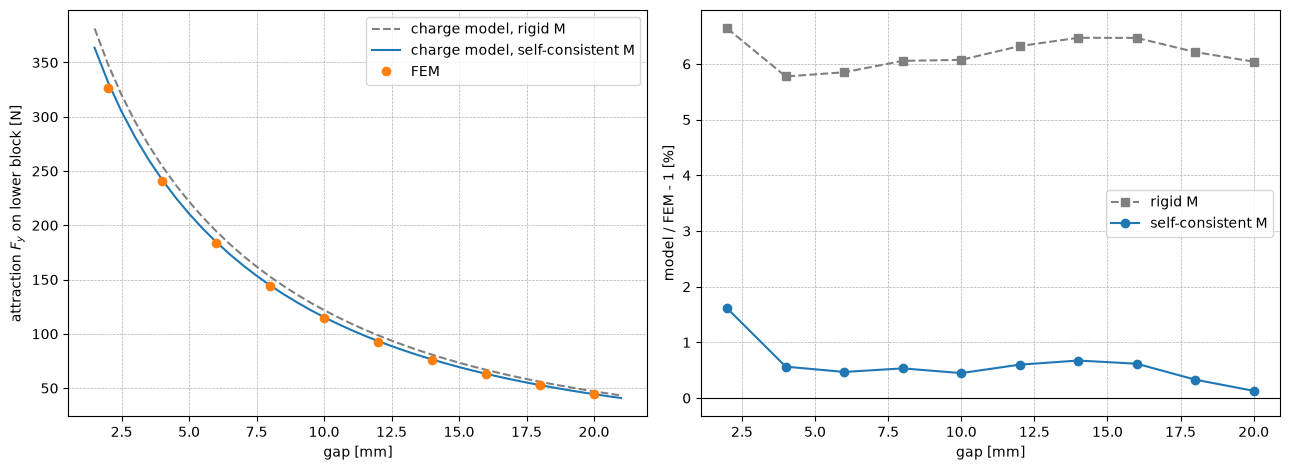

In [3]:
# 4. Force vs gap and the relative deviation
g_fine = np.linspace(1.5, 21, 40)
fine = np.array([model(g)[:2] for g in g_fine])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].plot(g_fine, fine[:, 0], "--", color="gray", label="charge model, rigid M")
ax[0].plot(g_fine, fine[:, 1], "-", label="charge model, self-consistent M")
ax[0].plot(cmp["Gap [mm]"], cmp["FEM F_y [N]"], "o", label="FEM")
ax[0].set_xlabel("gap [mm]")
ax[0].set_ylabel("attraction $F_y$ on lower block [N]")
ax[0].legend()
ax[0].grid(True, ls="--", lw=0.5)

ax[1].axhline(0, color="k", lw=0.8)
ax[1].plot(cmp["Gap [mm]"], cmp["rigid vs FEM [%]"], "s--", color="gray", label="rigid M")
ax[1].plot(cmp["Gap [mm]"], cmp["self-consistent vs FEM [%]"], "o-", label="self-consistent M")
ax[1].set_xlabel("gap [mm]")
ax[1].set_ylabel("model / FEM - 1 [%]")
ax[1].legend()
ax[1].grid(True, ls="--", lw=0.5)

plt.tight_layout()
plt.savefig("Images/Week6_ex4_force_vs_gap_charge_model.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

The two blocks attract, from 326.5 N at a 2 mm gap down to 44.3 N at 20 mm. That settles the magnetization question: they share one `N42` material and are both magnetized along +y. The original markdown's "magnetized in opposite directions" is wrong. The side forces stay under 0.8 N, no more than 0.7% of $F_y$.

The charge model with a rigid $M = \mu_r H_c$ comes out 5–7% high at every gap, the same pattern as the cylinder pair in Week5_ex1. Letting $M$ respond to the field fixes most of it. A 10 mm-thick block magnetized through its thin side has $N_\text{self} \approx 0.61$, so its own demagnetizing field lowers $M$ by about 2.5–2.8%, and the force, which goes as $M^2$, drops by about 5%. The other block's field ($N_\text{mut}$, 0.03–0.12) gives some of that back, more at small gaps. With that correction the model sits 0.1–0.7% above the FEM from 4 to 20 mm, and 1.6% above at 2 mm.

The 2 mm point is where a single uniform $M$ per block is weakest. With the blocks that close, the neighbor's field is strongest near the facing faces and edges, and that isn't uniform through the block. This is left as a candidate, not chased: the rest of the curve, including the steep rise at small gaps, follows the model to well under 1%. The gap sweep added to the original notebook gives a physically consistent force-vs-distance curve, and nothing here needs a further run.